# 04 · Root Cause Analysis

**CRISP-DM phase 4 — explanatory track.**

Phase 2 localised the problem: on **2023-05-08** stability dropped from ≈21.9 to ≈18.6 months in **3 reactors of Plant-04 (R03, R07, R08)**, while the other 34 reactors did not change.

Question for this notebook: **what changed in those reactors, and is it a credible cause?**

Approach — observational data, so causality is argued by accumulating evidence:
1. **What changed?** Compare every sensor: affected vs. control reactors, before vs. after (difference-in-differences logic).
2. **Timing** — does the change happen on the same day as the drop?
3. **Consistency** — does it happen in each affected reactor separately?
4. **Specificity** — does it happen *only* in the affected reactors?
5. **Dose-response** — more deviation → less stability?
6. **Alternatives** — can something else explain the drop (H4 sensor errors, pH / density shifts)?
7. **Fleet-wide drivers** — what drives stability in normal operation (H1, H5, plant differences)?

With ~250k rows, almost any difference is "statistically significant": we focus on **effect sizes with 95% confidence intervals**.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats

sys.path.insert(0, str(Path.cwd().parent / "src"))
from data import SENSORS, load_clean, load_config

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

TARGET = "stability_months"
RANGES = load_config()["normal_ranges"]
AFFECTED = ["P04-R03", "P04-R07", "P04-R08"]
CUT = pd.Timestamp("2023-05-08")

df = load_clean()
df["group"] = np.where(df["reactor_id"].isin(AFFECTED), "affected", "control")
df["period"] = np.where(df["date"] >= CUT, "after", "before")
print(df.shape)

(253856, 17)


## 1. What changed? Every sensor, affected vs. control, before vs. after
For each variable: change in the affected reactors **minus** change in the control reactors (*difference-in-differences*, DiD).
If the control group did not change, the DiD isolates what is specific to the affected reactors.
DiD is also expressed in **standard deviations** of the variable, to compare sensors on one scale.

In [2]:
def did(data, col):
    """Difference-in-differences of the mean of `col`, with a 95% CI (normal approximation)."""
    g = data.groupby(["group", "period"])[col].agg(["mean", "var", "count"])
    m, se2 = g["mean"], g["var"] / g["count"]
    est = (m["affected", "after"] - m["affected", "before"]) - (m["control", "after"] - m["control", "before"])
    se = np.sqrt(se2.sum())
    return est, est - 1.96 * se, est + 1.96 * se, 2 * stats.norm.sf(abs(est / se))

rows = []
for col in SENSORS + [TARGET]:
    est, lo, hi, p = did(df, col)
    rows.append({"variable": col, "DiD": est, "CI 95% low": lo, "CI 95% high": hi,
                 "DiD in SD": est / df[col].std(), "p-value": p})
did_table = pd.DataFrame(rows).set_index("variable")
did_table.round(4)

,DiD,CI 95% low,CI 95% high,DiD in SD,p-value
variable,,,,,
reaction_temperature_celsius,0.0506,-0.0572,0.1584,0.0137,0.3572
vessel_pressure_bar,-0.0027,-0.0077,0.0022,-0.0160,0.2830
refractive_index,0.0000,-0.0003,0.0003,0.0003,0.9841
density_g_cm3,0.0050,0.0047,0.0053,0.4276,0.0000
ph_level,0.0972,0.0887,0.1057,0.3340,0.0000
mixing_torque_nm,-1.2038,-1.2128,-1.1948,-3.0672,0.0000
mass_flow_rate_kg_h,0.2989,-0.7739,1.3717,0.0081,0.5850
stability_months,-3.2429,-3.2883,-3.1975,-1.5853,0.0000


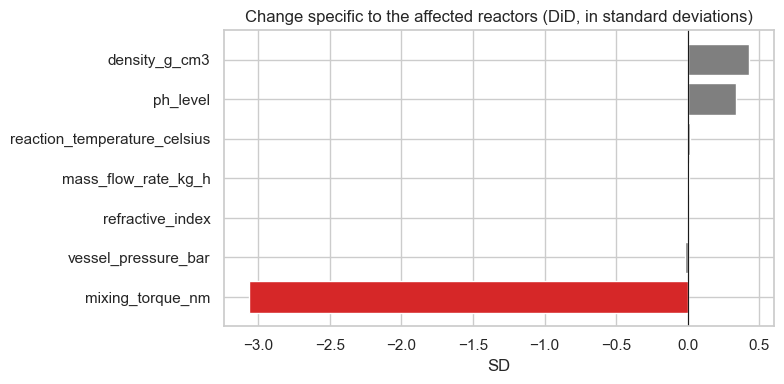

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
s = did_table.loc[SENSORS, "DiD in SD"].sort_values()
ax.barh(s.index, s.values, color=["tab:red" if abs(v) > 1 else "tab:gray" for v in s.values])
ax.axvline(0, c="k", lw=0.8)
ax.set(title="Change specific to the affected reactors (DiD, in standard deviations)", xlabel="SD")
plt.tight_layout(); plt.show()

**Mixing torque stands out**: −1.2 N·m, i.e. **−3 standard deviations**, specific to the affected reactors.
pH (+0.10) and density (+0.005) also shift a little (≈ 0.3–0.4 SD); the other sensors do not change.
With 7 sensors tested, a Bonferroni correction (p < 0.05 / 7 ≈ 0.007) does not change any conclusion.
The secondary pH / density shifts are examined in section 6.

## 2. Timing — does torque change on the same day as stability?

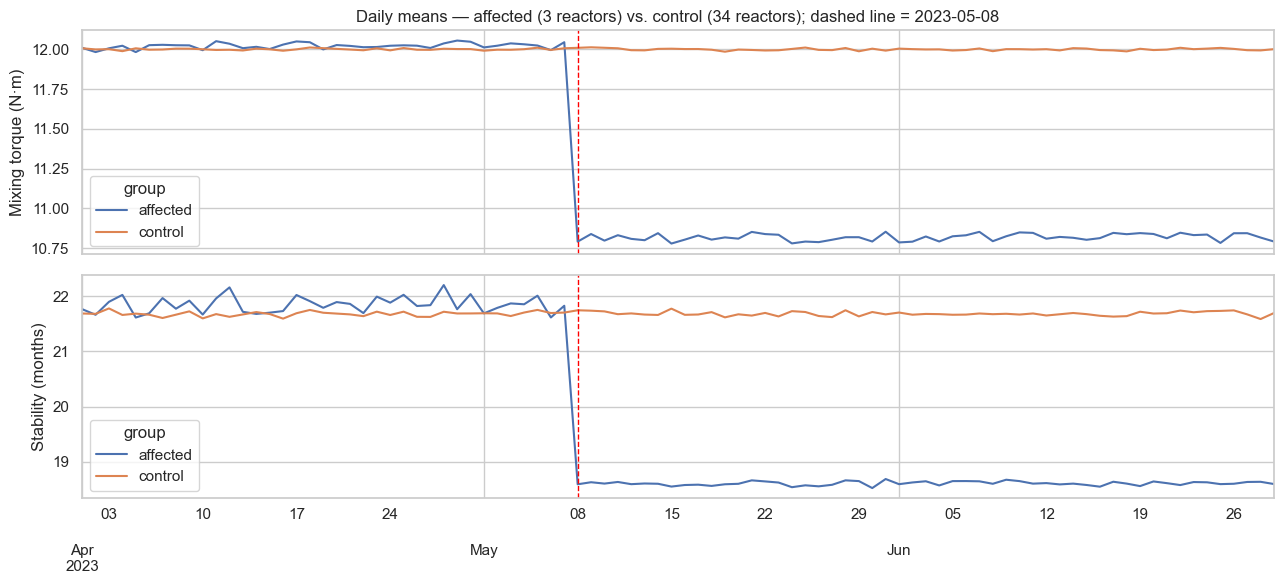

In [4]:
daily = df.groupby(["date", "group"])[["mixing_torque_nm", TARGET]].mean().unstack("group")
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
for ax, col, label in [(axes[0], "mixing_torque_nm", "Mixing torque (N·m)"), (axes[1], TARGET, "Stability (months)")]:
    daily[col].plot(ax=ax)
    ax.axvline(CUT, c="red", ls="--", lw=1)
    ax.set(ylabel=label, xlabel="")
axes[0].set_title("Daily means — affected (3 reactors) vs. control (34 reactors); dashed line = 2023-05-08")
plt.tight_layout(); plt.show()

In [5]:
df[df["group"] == "affected"].groupby("date")[["mixing_torque_nm", TARGET]].mean().loc["2023-05-05":"2023-05-10"].round(2)

,mixing_torque_nm,stability_months
date,,
2023-05-05,12.02,22.01
2023-05-06,12.00,21.62
2023-05-07,12.05,21.83
2023-05-08,10.79,18.59
2023-05-09,10.84,18.63
2023-05-10,10.80,18.61


Torque and stability change **on the same day**, as a step (not a drift): consistent with a discrete event on 8 May.

## 3. Consistency — each Plant-04 reactor separately

In [6]:
p4 = df[df["plant"] == "Plant-04"]
per_reactor = p4.pivot_table(index="reactor_id", columns="period", values=["mixing_torque_nm", TARGET], observed=True)
per_reactor = per_reactor.reindex(columns=["before", "after"], level=1).round(2)
per_reactor

mixing_torque_nm        stability_months       
period               before  after           before  after
reactor_id                                                
P04-R01               12.00  12.00            21.74  21.76
P04-R02               12.02  12.04            21.79  21.92
P04-R03               12.01  10.81            21.80  18.59
P04-R04               12.03  12.00            21.79  21.72
P04-R05               12.04  12.03            21.91  21.87
P04-R06               11.99  12.00            21.71  21.78
P04-R07               12.03  10.83            21.93  18.62
P04-R08               12.02  10.82            21.81  18.60

The same pattern appears **in each of the 3 affected reactors** (torque ≈ 12.0 → 10.8, stability ≈ 21.8 → 18.6); the other 5 reactors of the same plant do not change.

## 4. Specificity — how unusual is the new torque level?

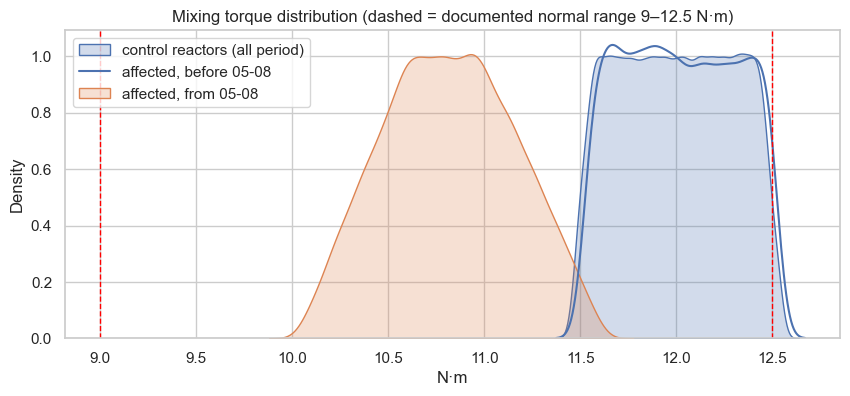

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.kdeplot(df.loc[df["group"] == "control", "mixing_torque_nm"], ax=ax, label="control reactors (all period)", fill=True)
sns.kdeplot(df.loc[(df["group"] == "affected") & (df["period"] == "before"), "mixing_torque_nm"], ax=ax, label="affected, before 05-08")
sns.kdeplot(df.loc[(df["group"] == "affected") & (df["period"] == "after"), "mixing_torque_nm"], ax=ax, label="affected, from 05-08", fill=True)
for v in RANGES["mixing_torque_nm"]:
    ax.axvline(v, c="red", ls="--", lw=1)
ax.set(title="Mixing torque distribution (dashed = documented normal range 9–12.5 N·m)", xlabel="N·m")
ax.legend(); plt.show()

In [8]:
low = df["mixing_torque_nm"] < 11.5
print(f"Torque < 11.5 N·m | control reactors: {low[df.group == 'control'].mean():.1%}"
      f"  | affected from 05-08: {low[(df.group == 'affected') & (df.period == 'after')].mean():.1%}")

Torque < 11.5 N·m | control reactors: 1.5%  | affected from 05-08: 91.9%


After 8 May the affected reactors operate in a torque regime that the rest of the fleet almost never reaches.
**Yet 10.8 N·m is inside the documented normal range (9–12.5)** → a univariate control on torque would raise no alarm.
This explains why the Quality team's usual controls did not catch it.

## 5. Dose-response — does lower torque mean lower stability?
Mean stability by torque bin, for control reactors and for the affected reactors after 8 May.

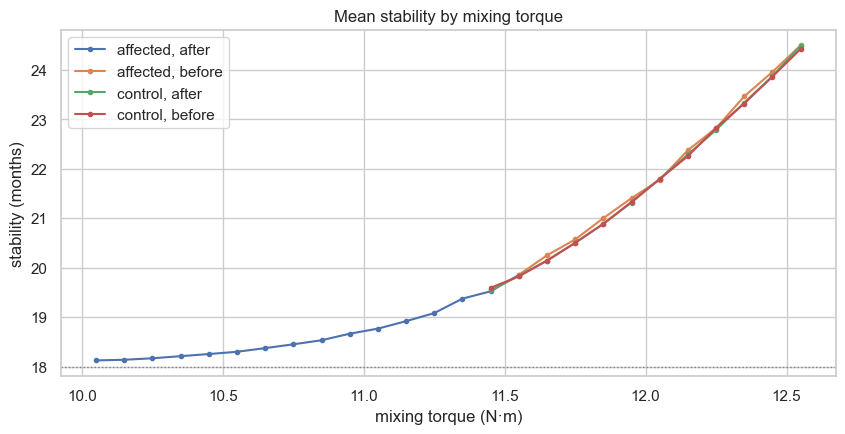

In [9]:
bins = np.arange(10.0, 12.65, 0.1)
b = df.assign(torque_bin=pd.cut(df["mixing_torque_nm"], bins))
curve = b.groupby(["torque_bin", "group", "period"], observed=True)[TARGET].agg(["mean", "count"]).reset_index()
curve = curve[curve["count"] >= 30]
curve["torque"] = curve["torque_bin"].apply(lambda i: i.mid).astype(float)

fig, ax = plt.subplots(figsize=(10, 4.5))
for (g, p), sub in curve.groupby(["group", "period"]):
    ax.plot(sub["torque"], sub["mean"], marker="o", ms=3, label=f"{g}, {p}")
ax.axhline(18, c="gray", ls=":", lw=1)
ax.set(title="Mean stability by mixing torque", xlabel="mixing torque (N·m)", ylabel="stability (months)")
ax.legend(); plt.show()

- In normal operation, stability rises **steadily with torque** (≈ +0.45 months per +0.1 N·m).
- The affected reactors after 8 May **continue the same curve** into a lower torque region → same mechanism, not something else.
- Below ≈ 11.3 N·m the curve flattens near **18 months, the bottom of the stability scale** (18–30 in the statement): a floor effect.
  That is why a straight-line extrapolation (−1.2 N·m × 4.5 ≈ −5.5 months) overestimates the real drop (−3.2 months): the relation is **non-linear** at the extremes.

## 6. Alternative explanations
### H4 — Plant-04 sensor error codes / °F readings

In [10]:
p4 = df[df["plant"] == "Plant-04"]
display(p4.pivot_table(index="group", columns="period", values="had_error_code", aggfunc="mean").round(4)
          .rename_axis(index="share of batches with error code"))
display(p4.groupby("had_error_code")[TARGET].mean().round(2).rename("Plant-04 mean stability"))

period,after,before
share of batches with error code,,
affected,0.0405,0.0358
control,0.0388,0.0402


had_error_code
False    21.06
True     21.00
Name: Plant-04 mean stability, dtype: float64

Error codes are equally frequent in affected and non-affected reactors, before and after 8 May, and batches with an error code have the same stability.
→ **H4 rejected**: the sensor problems of Plant-04 are a separate data-quality issue, not the cause of the drop.

### pH and density shifts in the affected reactors
Do they add anything once torque is accounted for? Linear regression within the 3 affected reactors (complete cases):

In [11]:
aff = df[df["group"] == "affected"].dropna(subset=["mixing_torque_nm", "ph_level", "density_g_cm3"])
aff = aff.assign(after=(aff["period"] == "after").astype(int))
m_aff = smf.ols(f"{TARGET} ~ mixing_torque_nm + ph_level + density_g_cm3 + after", data=aff).fit()
pd.DataFrame({"coef": m_aff.params, "CI 95% low": m_aff.conf_int()[0], "CI 95% high": m_aff.conf_int()[1]}).round(3)

,coef,CI 95% low,CI 95% high
Intercept,-6.084,-7.538,-4.630
mixing_torque_nm,2.284,2.230,2.337
ph_level,-0.015,-0.074,0.044
density_g_cm3,0.671,-0.802,2.145
after,-0.510,-0.584,-0.436


- **pH**: coefficient ≈ 0 → the +0.1 pH shift has no measurable effect on stability.
- **Density**: a +0.005 g/cm³ shift × its coefficient (≈ 0.7, CI includes 0) ≈ 0.003 months → negligible.
- **Torque** carries the effect. The remaining `after` term (≈ −0.5) reflects the non-linearity near the floor seen in section 5, not an extra cause.

## 7. Fleet-wide drivers of stability (normal operation)
What drives stability in the **34 control reactors**? Linear regression on complete cases.
Phase 2 suggested U-shapes for pH and pressure → squared terms included (`I(x**2)`).

In [12]:
ctrl = df[df["group"] == "control"].dropna(subset=SENSORS)
formulas = {
    "A: torque + temperature": f"{TARGET} ~ mixing_torque_nm + reaction_temperature_celsius",
    "B: A + pH² + pressure²": f"{TARGET} ~ mixing_torque_nm + reaction_temperature_celsius + ph_level + I(ph_level**2) + vessel_pressure_bar + I(vessel_pressure_bar**2)",
    "C: B + other sensors": f"{TARGET} ~ mixing_torque_nm + reaction_temperature_celsius + ph_level + I(ph_level**2) + vessel_pressure_bar + I(vessel_pressure_bar**2) + refractive_index + density_g_cm3 + mass_flow_rate_kg_h",
    "D: B + plant": f"{TARGET} ~ mixing_torque_nm + reaction_temperature_celsius + ph_level + I(ph_level**2) + vessel_pressure_bar + I(vessel_pressure_bar**2) + C(plant)",
}
fits = {name: smf.ols(f, data=ctrl).fit() for name, f in formulas.items()}
pd.DataFrame({"R²": {n: m.rsquared for n, m in fits.items()}, "n": {n: int(m.nobs) for n, m in fits.items()}}).round(3)

,R²,n
A: torque + temperature,0.618,139253
B: A + pH² + pressure²,0.782,139253
C: B + other sensors,0.798,139253
D: B + plant,0.782,139253


- Torque + temperature alone explain ~62% of the variance; adding the **U-shapes of pH and pressure** brings it to ~78%.
- The other three sensors add almost nothing (+0.016).
- Adding the plant adds **nothing** → the differences between plants (e.g. Plant-01 ≈ 22.0 vs Plant-02 ≈ 21.4 months) are explained by their operating conditions, not by something plant-specific.

In [13]:
mB = fits["B: A + pH² + pressure²"]
coef = pd.DataFrame({"coef": mB.params, "CI 95% low": mB.conf_int()[0], "CI 95% high": mB.conf_int()[1]}).round(3)
display(coef)
ph_opt = -mB.params["ph_level"] / (2 * mB.params["I(ph_level ** 2)"])
p_opt = -mB.params["vessel_pressure_bar"] / (2 * mB.params["I(vessel_pressure_bar ** 2)"])
print(f"Optimum pH ≈ {ph_opt:.2f} (normal range 5.0–6.0) | optimum pressure ≈ {p_opt:.2f} bar (normal range 2–3)")
print(f"Torque: +{mB.params['mixing_torque_nm']:.2f} months per +1 N·m | temperature: {mB.params['reaction_temperature_celsius']:.2f} months per +1 °C")

,coef,CI 95% low,CI 95% high
Intercept,-362.377,-364.520,-360.234
mixing_torque_nm,4.540,4.523,4.557
reaction_temperature_celsius,-0.216,-0.217,-0.215
ph_level,94.819,94.129,95.509
I(ph_level ** 2),-8.619,-8.682,-8.557
vessel_pressure_bar,76.978,76.123,77.832
I(vessel_pressure_bar ** 2),-16.720,-16.905,-16.535


Optimum pH ≈ 5.50 (normal range 5.0–6.0) | optimum pressure ≈ 2.30 bar (normal range 2–3)
Torque: +4.54 months per +1 N·m | temperature: -0.22 months per +1 °C


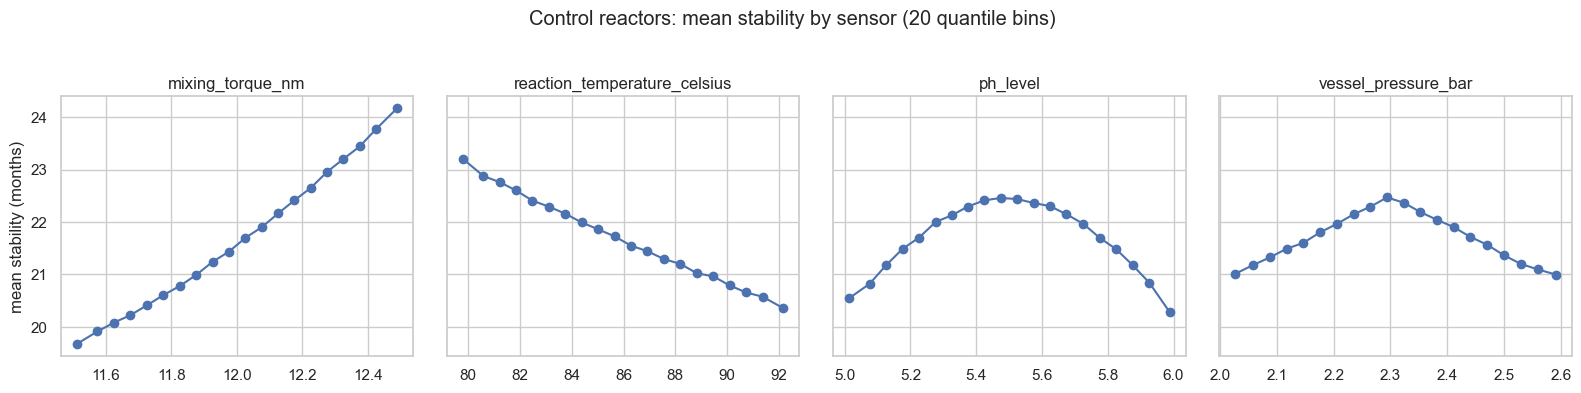

In [14]:
plot_vars = ["mixing_torque_nm", "reaction_temperature_celsius", "ph_level", "vessel_pressure_bar"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, c in zip(axes, plot_vars):
    g = ctrl.groupby(pd.qcut(ctrl[c], 20), observed=True).agg(x=(c, "mean"), y=(TARGET, "mean"))
    ax.plot(g["x"], g["y"], marker="o")
    ax.set(title=c, xlabel="")
axes[0].set_ylabel("mean stability (months)")
fig.suptitle("Control reactors: mean stability by sensor (20 quantile bins)", y=1.03)
plt.tight_layout(); plt.show()

In normal operation, stability is highest with **high torque, low temperature, pH ≈ 5.5 and pressure ≈ 2.3 bar** — all inside the normal ranges.
The normal ranges are therefore *acceptable* ranges, not *optimal* ones: within them, stability still varies by several months.

## 8. Conclusions

**Root cause (proximate)** — From **2023-05-08**, the **mixing torque of Plant-04 reactors R03, R07 and R08 dropped by ≈1.2 N·m** (12.0 → 10.8).
Evidence:
| Criterion | Result |
|---|---|
| Size | −3 SD; the largest change of any sensor (DiD) |
| Timing | Torque and stability step on the same day |
| Consistency | Same change in each of the 3 reactors |
| Specificity | No change in the other 5 Plant-04 reactors or in the other 34 reactors |
| Dose-response | Affected reactors follow the same torque–stability curve as the rest of the fleet |
| Alternatives | H4 (sensor errors) rejected; pH / density shifts have negligible effect |
| Plausibility | Lower agitation → less homogeneous reaction → more by-products → faster oxidation |

**Why nobody noticed** — 10.8 N·m is within the documented normal range (9–12.5 N·m).

**What the data cannot say (root cause)** — *why* torque dropped: a mechanical problem of the agitators (motor, impeller wear, setting changed during maintenance) or a change in the viscosity of the charge. Unchanged refractive index (composition fingerprint) points more towards a mechanical / setting cause, but this must be **verified on site** (maintenance and change logs of the three reactors around 8 May).

**Fleet-wide drivers (normal operation)** — stability increases with torque (+4.5 months per N·m) and decreases with temperature (−0.22 months per °C); pH and pressure have an optimum near the centre of their ranges (≈ 5.5 and ≈ 2.3 bar). Plant differences are explained by these operating conditions.

**Recommendations**
1. Inspect the agitators of P04-R03/R07/R08 and their change history around 8 May; restore torque to ≈ 12 N·m.
2. Add an alarm on low torque (e.g. < 11.5 N·m) — the current normal range is too wide to protect stability.
3. Consider operating targets, not just ranges: higher torque, lower temperature, pH ≈ 5.5, pressure ≈ 2.3 bar.
4. Confirm causality with a controlled trial on one reactor (vary torque, measure stability).